In [ ]:
#importer les bibliothèques
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.utils import load_img, img_to_array  # <- correction pour charger les images


In [ ]:
# Dataset : Flowers Recognition
!pip install kagglehub
import kagglehub

# Téléchargement de dataset
path = kagglehub.dataset_download("waseemalastal/the-oxford-flowers-102-dataset")
print("Dataset téléchargé à :", path)

# Chemin vers les images
base_dir = '/kaggle/input/the-oxford-flowers-102-dataset/jpg'  # vérifier le dossier exact des images
classes = list(train_generator.class_indices.keys())



Using Colab cache for faster access to the 'the-oxford-flowers-102-dataset' dataset.
Dataset téléchargé à : /kaggle/input/the-oxford-flowers-102-dataset


In [ ]:
import os

base_dir = '/kaggle/input/the-oxford-flowers-102-dataset'

print(os.listdir(base_dir))


['flower_data']


In [ ]:
import os

base_dir = '/kaggle/input/the-oxford-flowers-102-dataset/flower_data'
classes = os.listdir(base_dir)
classes.sort()

print(f"Nombre de classes : {len(classes)}")
print("Exemples de classes :", classes[:10])

Nombre de classes : 4
Exemples de classes : ['cat_to_name.json', 'test', 'train', 'valid']


In [ ]:
import os
import json

base_dir = '/kaggle/input/the-oxford-flowers-102-dataset/flower_data/train'

classes = os.listdir(base_dir)
classes.sort()
print(f"Nombre de classes dans l'entraînement : {len(classes)}")
print("Exemples de classes :", classes[:10])

mapping_file = '/kaggle/input/the-oxford-flowers-102-dataset/flower_data/cat_to_name.json'
with open(mapping_file) as f:
    cat_to_name = json.load(f)

print("Exemple de mapping :", list(cat_to_name.items())[:5])


Nombre de classes dans l'entraînement : 102
Exemples de classes : ['1', '10', '100', '101', '102', '11', '12', '13', '14', '15']
Exemple de mapping : [('21', 'fire lily'), ('3', 'canterbury bells'), ('45', 'bolero deep blue'), ('1', 'pink primrose'), ('34', 'mexican aster')]


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

img_height, img_width = 224, 224
batch_size = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

valid_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    '/kaggle/input/the-oxford-flowers-102-dataset/flower_data/train',
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

validation_generator = valid_datagen.flow_from_directory(
    '/kaggle/input/the-oxford-flowers-102-dataset/flower_data/valid',
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)


Found 6552 images belonging to 102 classes.
Found 818 images belonging to 102 classes.


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
predictions = Dense(102, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,435,110 (9.29 MB)

 Trainable params: 2,032,230 (7.75 MB)

 Non-trainable params: 402,880 (1.54 MB)

In [ ]:
epochs = 10

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=epochs
)


Epoch 1/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 181s 786ms/step - accuracy: 0.2331 - loss: 3.7702 - val_accuracy: 0.4792 - val_loss: 2.2641
Epoch 2/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 97s 474ms/step - accuracy: 0.8404 - loss: 0.8472 - val_accuracy: 0.6907 - val_loss: 1.1791
Epoch 3/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 97s 469ms/step - accuracy: 0.9426 - loss: 0.2974 - val_accuracy: 0.8447 - val_loss: 0.6286
Epoch 4/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 98s 476ms/step - accuracy: 0.9754 - loss: 0.1542 - val_accuracy: 0.8961 - val_loss: 0.4062
Epoch 5/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 96s 467ms/step - accuracy: 0.9846 - loss: 0.0973 - val_accuracy: 0.9230 - val_loss: 0.3034
Epoch 6/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 98s 476ms/step - accuracy: 0.9911 - loss: 0.0649 - val_accuracy: 0.9181 - val_loss: 0.3005
Epoch 7/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 103s 502ms/step - accuracy: 0.9929 - loss: 0.0506 - val_accuracy: 0.9340 - val_loss: 0.2489
Epoch 8/10
205/205 ━━━━━━━━━━━━━━━━━━━━ 103s 501ms/step - accuracy: 0.9955 - loss

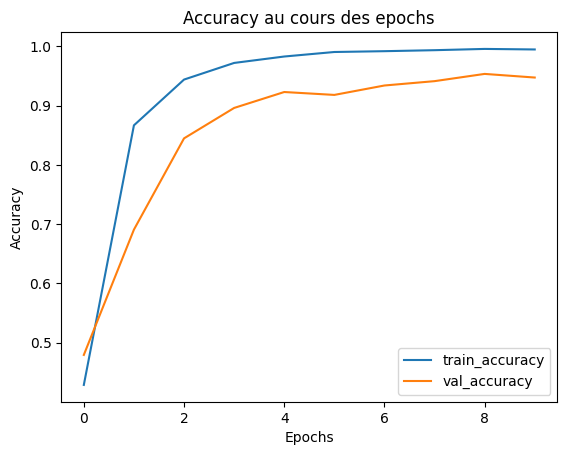

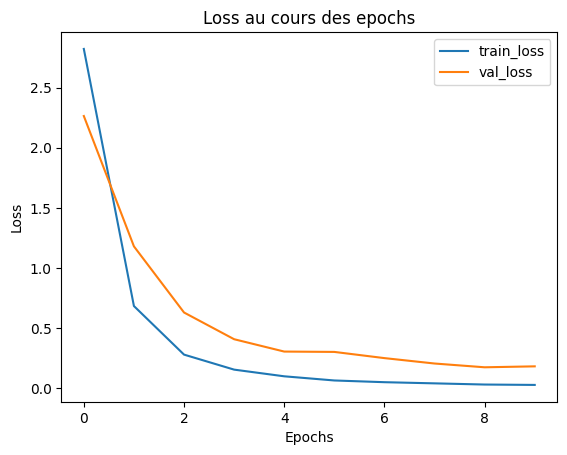

In [ ]:


# Accuracy
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Accuracy au cours des epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Loss au cours des epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

def test_image():

    uploaded = files.upload()
    img_name = list(uploaded.keys())[0]


    true_class_name = input(f"Entrez la vraie classe pour l'image '{img_name}': ")


    img_path = img_name
    img = image.load_img(img_path, target_size=(img_height, img_width))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    # Prédiction
    pred_class_num = list(train_generator.class_indices.keys())[np.argmax(model.predict(img_array))]
    pred_class_name = cat_to_name[pred_class_num]

    # Affichage
    plt.imshow(img)
    plt.title(f"Prédit: {pred_class_name}\nCorrect: {true_class_name}")
    plt.axis('off')
    plt.show()

    print(f"Image: {img_name} → Prédit: {pred_class_name}, Correct: {true_class_name}")




In [ ]:
import os
import json

base_dir = "/kaggle/input/the-oxford-flowers-102-dataset/flower_data"
cat_to_name_path = os.path.join(base_dir, "cat_to_name.json")

with open(cat_to_name_path, 'r') as f:
    cat_to_name = json.load(f)

print("Nombre de classes :", len(cat_to_name))
print("Exemple de classes (numéro → nom) :")
for class_num, class_name in cat_to_name.items():
    print(f"{class_num} → {class_name}")

Nombre de classes : 102
Exemple de classes (numéro → nom) :
21 → fire lily
3 → canterbury bells
45 → bolero deep blue
1 → pink primrose
34 → mexican aster
27 → prince of wales feathers
7 → moon orchid
16 → globe-flower
25 → grape hyacinth
26 → corn poppy
79 → toad lily
39 → siam tulip
24 → red ginger
67 → spring crocus
35 → alpine sea holly
32 → garden phlox
10 → globe thistle
6 → tiger lily
93 → ball moss
33 → love in the mist
9 → monkshood
102 → blackberry lily
14 → spear thistle
19 → balloon flower
100 → blanket flower
13 → king protea
49 → oxeye daisy
15 → yellow iris
61 → cautleya spicata
31 → carnation
64 → silverbush
68 → bearded iris
63 → black-eyed susan
69 → windflower
62 → japanese anemone
20 → giant white arum lily
38 → great masterwort
4 → sweet pea
86 → tree mallow
101 → trumpet creeper
42 → daffodil
22 → pincushion flower
2 → hard-leaved pocket orchid
54 → sunflower
66 → osteospermum
70 → tree poppy
85 → desert-rose
99 → bromelia
87 → magnolia
5 → english marigold
92 → b

Saving pink primose.PNG to pink primose (4).PNG
Entrez la vraie classe pour l'image 'pink primose (4).PNG': pink primose
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


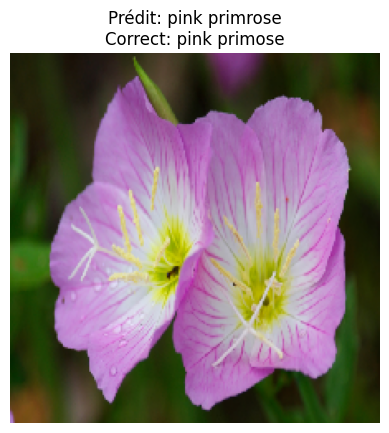

Image: pink primose (4).PNG → Prédit: pink primrose, Correct: pink primose


In [ ]:
 #test1
 test_image()

Saving waterlily.PNG to waterlily (1).PNG
Entrez la vraie classe pour l'image 'waterlily (1).PNG': water lily
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


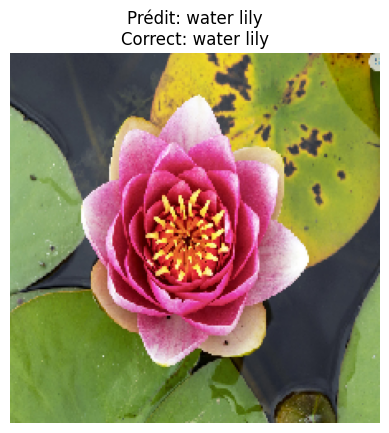

Image: waterlily (1).PNG → Prédit: water lily, Correct: water lily


In [ ]:
#test2
test_image()


Saving redginger.PNG to redginger (4).PNG
Entrez la vraie classe pour l'image 'redginger (4).PNG': red ginger
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


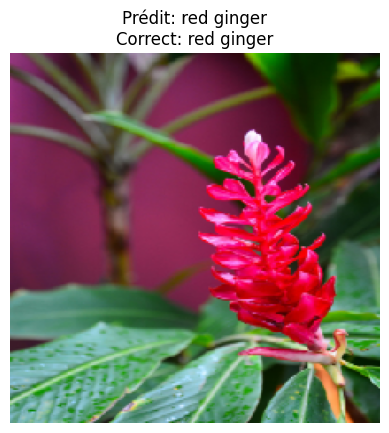

Image: redginger (4).PNG → Prédit: red ginger, Correct: red ginger


In [ ]:
#test3
test_image()

Saving firelily.PNG to firelily (1).PNG
Entrez la vraie classe pour l'image 'firelily (1).PNG': fire lily
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


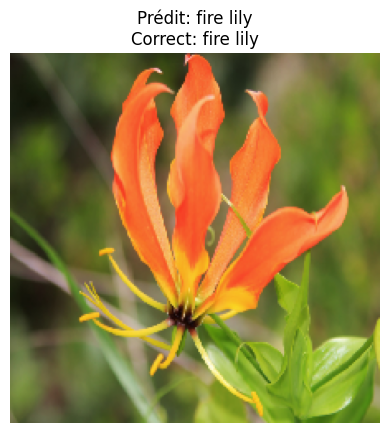

Image: firelily (1).PNG → Prédit: fire lily, Correct: fire lily


In [ ]:
#test4
test_image()

Saving foxglove.PNG to foxglove (2).PNG
Entrez la vraie classe pour l'image 'foxglove (2).PNG': foxglove
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


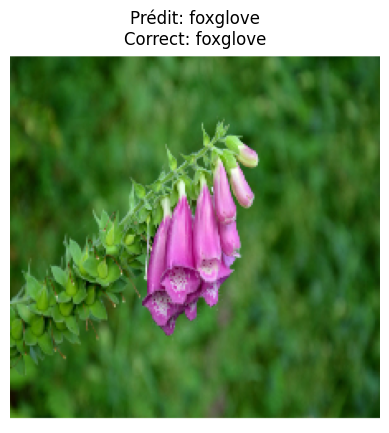

Image: foxglove (2).PNG → Prédit: foxglove, Correct: foxglove


In [ ]:
#test5
test_image()

Saving rose1.PNG to rose1 (3).PNG
Entrez la vraie classe pour l'image 'rose1 (3).PNG': rose
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


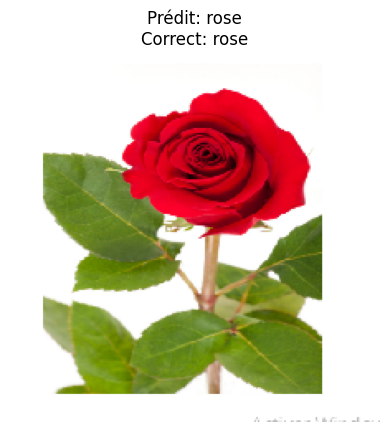

Image: rose1 (3).PNG → Prédit: rose, Correct: rose


In [ ]:
#test6
test_image()


Saving sunflower.PNG to sunflower (7).PNG
Entrez la vraie classe pour l'image 'sunflower (7).PNG': sunflower
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


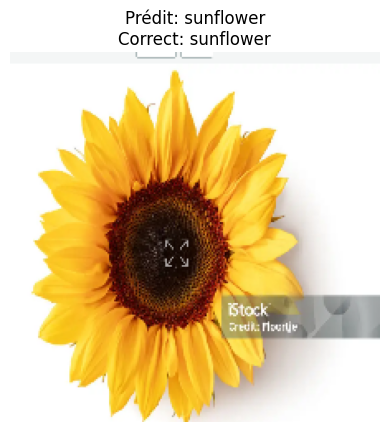

Image: sunflower (7).PNG → Prédit: sunflower, Correct: sunflower


In [ ]:
#test7
test_image()

Saving daisyPNG.PNG to daisyPNG (3).PNG
Entrez la vraie classe pour l'image 'daisyPNG (3).PNG': oxeye daisy
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


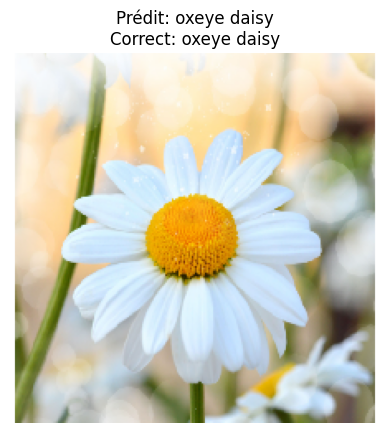

Image: daisyPNG (3).PNG → Prédit: oxeye daisy, Correct: oxeye daisy


In [ ]:
#test8
test_image()


Saving corn poppy.PNG to corn poppy.PNG
Entrez la vraie classe pour l'image 'corn poppy.PNG': corn poppy
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


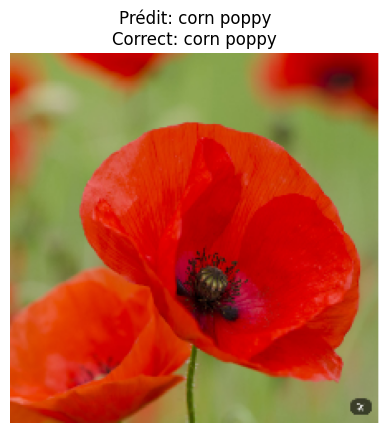

Image: corn poppy.PNG → Prédit: corn poppy, Correct: corn poppy


In [ ]:
#test9
test_image()

Saving tiggerlilly.PNG to tiggerlilly.PNG
Entrez la vraie classe pour l'image 'tiggerlilly.PNG': Tiger Lily
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


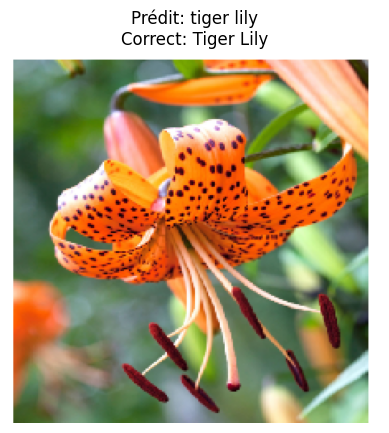

Image: tiggerlilly.PNG → Prédit: tiger lily, Correct: Tiger Lily


In [ ]:
#test10
test_image()

Saving king.PNG to king.PNG
Entrez la vraie classe pour l'image 'king.PNG': King Protea
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


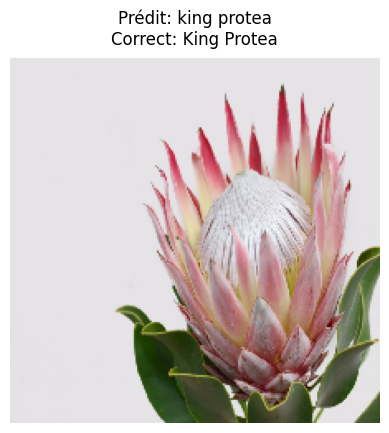

Image: king.PNG → Prédit: king protea, Correct: King Protea


In [ ]:
#test11
test_image()

Saving great.PNG to great (2).PNG
Entrez la vraie classe pour l'image 'great (2).PNG': Great Masterwort
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


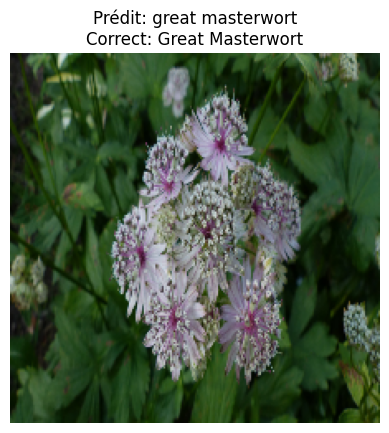

Image: great (2).PNG → Prédit: great masterwort, Correct: Great Masterwort


In [ ]:
#test12
test_image()

Saving sweet.PNG to sweet (1).PNG
Entrez la vraie classe pour l'image 'sweet (1).PNG': sweet pea
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


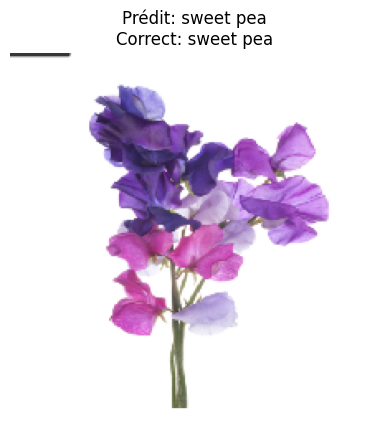

Image: sweet (1).PNG → Prédit: sweet pea, Correct: sweet pea


In [ ]:
#test13
test_image()

Saving bee.PNG to bee.PNG
Entrez la vraie classe pour l'image 'bee.PNG': bee balm
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


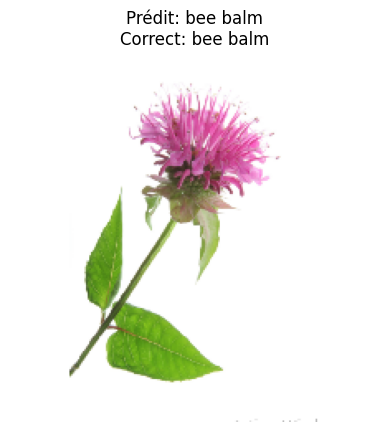

Image: bee.PNG → Prédit: bee balm, Correct: bee balm


In [ ]:
#test14
test_image()

Saving s.PNG to s.PNG
Entrez la vraie classe pour l'image 's.PNG': Stemless Gentian 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


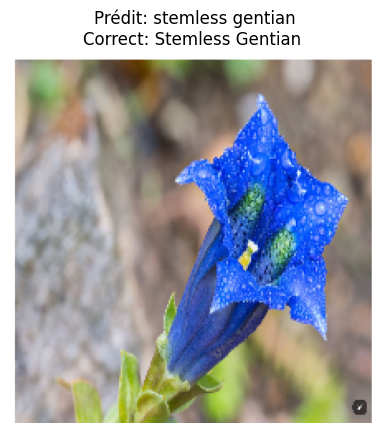

Image: s.PNG → Prédit: stemless gentian, Correct: Stemless Gentian 


In [ ]:
#test15
test_image()